Explore every event of all magnitudes in the regional input before clustering. The selected polygonal fault corridor is an approximation; events may include background or adjacent-fault seismicity. The source and bounds are described in [the example data notes](../examples/SAN_JACINTO_REGION.md). NNA applies the configurable QTM magnitude cutoff (M ≥ 0.3 in this example).

Catalog: examples/san_jacinto_region_qtm.csv


All-magnitude input events: 288,129
NNA magnitude cutoff: M ≥ 0.3; eligible: 80,574; below cutoff: 207,555
Date range: 2008-01-01 00:04:12.531000+00:00 to 2017-12-31 23:44:19.261000+00:00 UTC


,datetime,lon,lat,dep,mag
count,288129,288129.000000,288129.000000,288129.000000,288129.000000
mean,2013-05-07 11:37:32.819841024+00:00,-116.624437,33.538429,10.282368,0.051580
min,2008-01-01 00:04:12.531000+00:00,-117.657620,32.865850,-0.968000,-1.760000
25%,2010-09-08 15:45:56.857999872+00:00,-116.758050,33.463440,7.531000,-0.350000
50%,2013-05-08 03:08:32.460999936+00:00,-116.572840,33.495930,9.891000,-0.060000
75%,2015-11-28 12:20:31.740999936+00:00,-116.459220,33.614370,13.227000,0.360000
max,2017-12-31 23:44:19.261000+00:00,-115.791600,34.283350,31.390000,5.430000
std,NaN,0.261160,0.201731,3.747824,0.567306


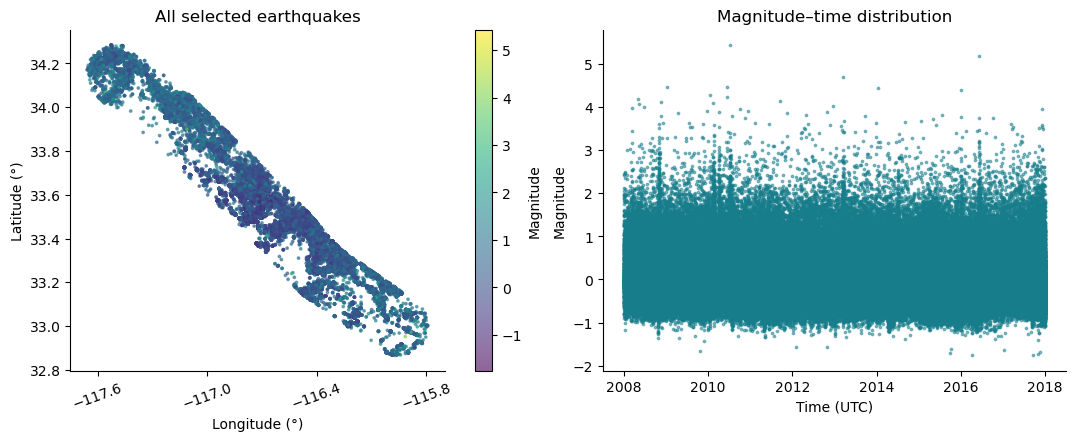

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

here = Path.cwd().resolve()
root = next((p for p in (here, *here.parents) if (p / "run_aspect.py").is_file()), None)
assert root is not None, "Open the notebook from within the ASPECT repository."
sys.path.insert(0, str(root / "notebooks"))
import regional_utils as w
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

print("Catalog:", Path(w.CFG["data_sources"]["QTM"]).relative_to(w.ROOT))
catalog = pd.read_csv(w.CFG["data_sources"]["QTM"])
catalog["datetime"] = pd.to_datetime(catalog["datetime"], format="mixed", utc=True)
threshold = w.CFG["nna_params"]["mag_thresholds"]["QTM"]
print(f"All-magnitude input events: {len(catalog):,}")
print(f"NNA magnitude cutoff: M ≥ {threshold:g}; eligible: {(catalog.mag >= threshold).sum():,}; below cutoff: {(catalog.mag < threshold).sum():,}")
print(f"Date range: {catalog.datetime.min()} to {catalog.datetime.max()} UTC")
display(catalog[["datetime", "lon", "lat", "dep", "mag"]].describe(include="all"))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3), constrained_layout=True)
sc = ax[0].scatter(catalog.lon, catalog.lat, c=catalog.mag, s=3, cmap="viridis", alpha=.6, rasterized=True)
ax[0].set(xlabel="Longitude (°)", ylabel="Latitude (°)", title="All selected earthquakes")
ax[0].set_aspect(1 / np.cos(np.deg2rad(catalog.lat.mean())))
ax[0].xaxis.set_major_locator(plt.MaxNLocator(4))
ax[0].tick_params(axis="x", rotation=20)
fig.colorbar(sc, ax=ax[0], label="Magnitude")
ax[1].scatter(catalog.datetime, catalog.mag, s=3, color="#177d8b", alpha=.5, rasterized=True)
ax[1].set(xlabel="Time (UTC)", ylabel="Magnitude", title="Magnitude–time distribution")
fig.autofmt_xdate(); plt.show()

Proceed to `01_nna.ipynb`. Notebook 01 runs the algorithm; notebooks 02–04 require the preceding stage. Results are written to the configured regional output directory. Stage hashes detect changes to inputs, parameters, code, or prior outputs.